# Seasonal patterns in BFRO reports
IS445 · Homework 5 · Python + Altair + Vega-Lite

Two original views of the same permitted BFRO dataset: a state-by-season share heatmap and a season-by-class stacked bar chart. The source URL is read directly below. These are reports, not verified animal observations or population-adjusted rates. The `season` field is used as supplied; no season is inferred from an often incomplete date.

[Source CSV](https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/bfro_reports_fall2022.csv) · [Course dataset documentation](https://github.com/UIUC-iSchool-DataViz/is445_data#bigfoot-sightings-dataset) · [Interactive Jekyll page](https://terryhu2.github.io/hw5/)

Install the versions in `requirements-hw5.txt` if needed. Run all cells from top to bottom. The final cell exports the exact Vega-Lite specifications embedded in the webpage. Static previews are included so GitHub can render the notebook without executing JavaScript.

In [1]:
import json
from pathlib import Path
import pandas as pd
import altair as alt
import vl_convert as vlc
from IPython.display import display, Image

DATA_URL = "https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/bfro_reports_fall2022.csv"
raw = pd.read_csv(DATA_URL)
print(f"pandas {pd.__version__}; Altair {alt.__version__}")
print(f"Source: {len(raw):,} rows, {len(raw.columns)} columns")

pandas 3.1.1; Altair 6.3.0
Source: 4,747 rows, 29 columns


## Cleaning and aggregation
Keep only the state, recorded season, report class, and report ID; narrative text and precise locations are never exported. Trim category whitespace, exclude unknown or missing seasons, and require a state and one of the three recorded classes. Report IDs are unique in this snapshot, so no deduplication changes the data. Aggregate counts by state × season × class. Reindex to include absent combinations as zero: zero is a count of no records in this snapshot, not evidence of no real-world events. Both plots use this same cleaned population. Rank the 12 displayed states once using all retained classes combined, with alphabetical tie-breaking, so changing class cannot silently change the comparison group.

In [2]:
SEASONS = ["Spring", "Summer", "Fall", "Winter"]
CLASSES = ["Class A", "Class B", "Class C"]
clean = raw[["number", "state", "season", "classification"]].copy()
for col in ["state", "season", "classification"]:
    clean[col] = clean[col].astype("string").str.strip()
assert clean["number"].notna().all() and clean["number"].is_unique
valid = (clean["state"].notna() & clean["state"].ne("")
         & clean["season"].isin(SEASONS)
         & clean["classification"].isin(CLASSES))
clean = clean.loc[valid].copy()
states = sorted(clean["state"].unique().tolist())
grid = pd.MultiIndex.from_product([states, SEASONS, CLASSES],
                                  names=["state", "season", "classification"])
counts = (clean.groupby(["state", "season", "classification"]).size()
          .reindex(grid, fill_value=0).rename("reports").reset_index())
ranking = (clean.groupby("state").size().rename("total").reset_index()
           .sort_values(["total", "state"], ascending=[False, True]))
top_states = ranking.head(12)["state"].tolist()
assert counts["reports"].sum() == len(clean)
print(f"Retained {len(clean):,} reports in {len(states)} states; excluded {len(raw)-len(clean):,} rows.")
print("Excluded season values:", raw.loc[~valid, "season"].value_counts(dropna=False).to_dict())
display(ranking.head(12))
display(clean["season"].value_counts().reindex(SEASONS).rename("reports").to_frame())

Retained 4,656 reports in 49 states; excluded 91 rows.
Excluded season values: {'Unknown': 91}


,state,total
45,Washington,553
4,California,397
8,Florida,283
33,Ohio,270
35,Oregon,237
11,Illinois,230
41,Texas,207
20,Michigan,205
23,Missouri,139
9,Georgia,119


,reports
season,
Spring,767
Summer,1765
Fall,1413
Winter,711


## Plot 1 · Where does each state's reporting peak?
The heatmap compares the seasonal distribution of reports in the 12 states with the most retained reports. Season is ordered categorical (`O`) on x; state is nominal (`N`) on y, ordered by the fixed ranking above. Cell color encodes a quantitative (`Q`) within-state share using sequential blue: darker means a larger share, not a different class. Every row is normalized separately, so high-volume states do not dominate. Text labels and tooltips give exact percentages and denominators. A fixed 0–100% color domain permits comparison across filter settings. The class dropdown filters the aggregated counts **before** summing and recalculating each state's denominator. A zero denominator is displayed as an em dash rather than a misleading 0%.

This differs from the course's BFRO longitude/latitude scatterplots, pressure coloring, and longitude histograms.

alt.LayerChart(...)

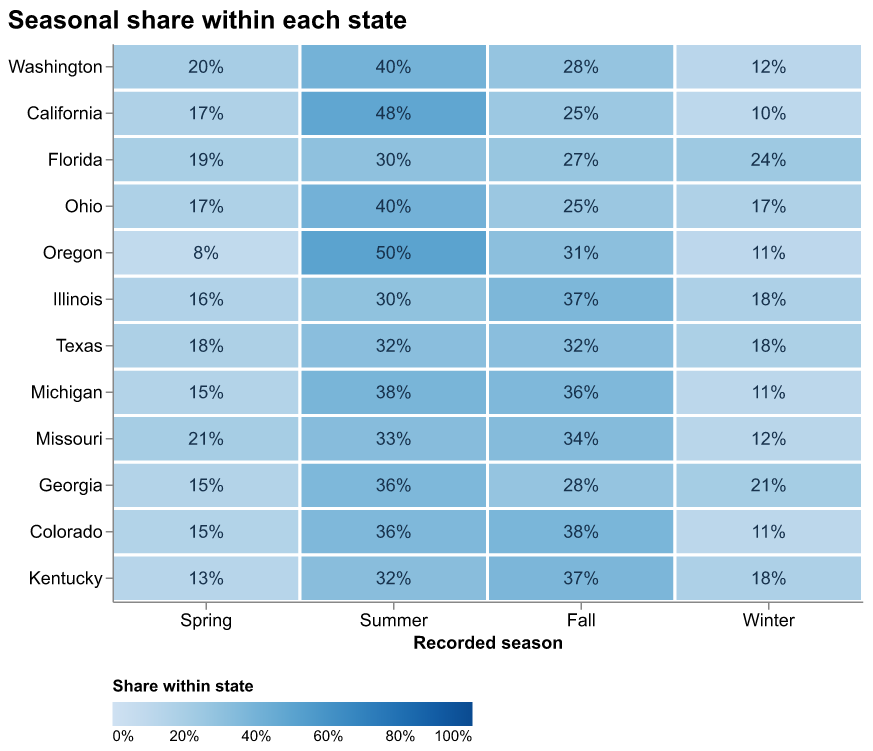

In [3]:
report_class = alt.param(
    name="report_class", value="All classes",
    bind=alt.binding_select(options=["All classes"] + CLASSES, name="Report class: "))
heat_base = (alt.Chart(counts[counts["state"].isin(top_states)])
    .add_params(report_class)
    .transform_filter((report_class == "All classes") |
                      (alt.datum.classification == report_class))
    .transform_aggregate(reports="sum(reports)", groupby=["state", "season"])
    .transform_joinaggregate(state_total="sum(reports)", groupby=["state"])
    .transform_calculate(share="datum.state_total > 0 ? datum.reports / datum.state_total : null",
                         share_label="datum.state_total > 0 ? format(datum.reports / datum.state_total, '.0%') : '—'")
    .encode(
        x=alt.X("season:O", sort=SEASONS, title="Recorded season", axis=alt.Axis(labelAngle=0)),
        y=alt.Y("state:N", sort=top_states, title=None),
        tooltip=[alt.Tooltip("state:N", title="State"), alt.Tooltip("season:O", title="Season"),
                 alt.Tooltip("reports:Q", title="Reports", format=","),
                 alt.Tooltip("state_total:Q", title="State total (selected class)", format=","),
                 alt.Tooltip("share:Q", title="Within-state share", format=".1%")]))
heat_cells = heat_base.mark_rect(stroke="white", strokeWidth=2).encode(
    color=alt.Color("share:Q", title="Share within state",
                    scale=alt.Scale(scheme="blues", domain=[0, 1]),
                    legend=alt.Legend(format=".0%", orient="bottom", gradientLength=240)))
heat_labels = heat_base.mark_text(fontSize=12).encode(
    text="share_label:N",
    color=alt.condition(alt.datum.share >= 0.55, alt.value("white"), alt.value("#17324d")))
heatmap = (heat_cells + heat_labels).properties(
    width=500, height=372, title="Seasonal share within each state").configure_view(stroke=None).configure_axis(
        labelFontSize=12, titleFontSize=12, grid=False).configure_title(anchor="start", fontSize=17)
display(heatmap)
display(Image(vlc.vegalite_to_png(heatmap.to_dict(), scale=1.5)))

## Plot 2 · How many reports, and which classes?
The stacked bar chart shows the number of reports in each recorded season, subdivided by report class. Season is ordinal (`O`) on x, the summed number of reports is quantitative (`Q`) on y with a zero baseline, and class is nominal (`N`) in the fill. Blue, orange, and purple distinguish the three classes without suggesting a numerical ranking; this categorical palette has a different role from the heatmap's sequential blues. Stacked height conveys each seasonal total, while tooltips give each segment's count. The same zero-filled state × season × class count table is filtered using the state dropdown and then summed over states in Vega-Lite. No weather imputation, date parsing, or sampling is performed. The y-axis rescales when the state changes; compare magnitudes using the tick labels rather than bar heights across different selections.

Use the state dropdown to isolate Illinois or another state, then restore All states. This changes the plotted data, beyond pan/zoom, making local seasonal patterns visible without national totals obscuring them. The heatmap's separate class filter lets readers ask whether its seasonal pattern holds within a report class. The two controls are independent. Hover either chart for counts; the heatmap also reports its current denominator.

alt.Chart(...)

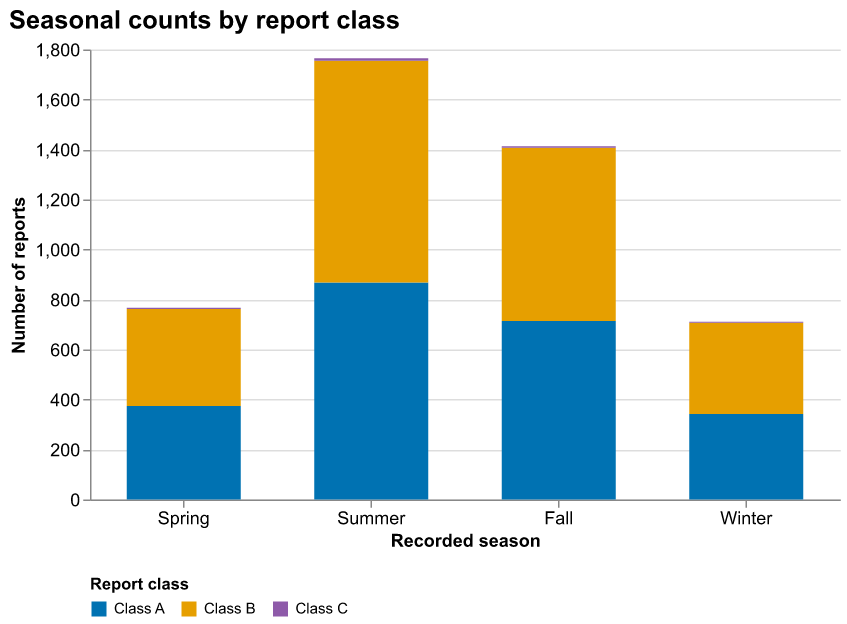

In [4]:
selected_state = alt.param(
    name="selected_state", value="All states",
    bind=alt.binding_select(options=["All states"] + states, name="State: "))
bars = (alt.Chart(counts).add_params(selected_state)
    .transform_filter((selected_state == "All states") | (alt.datum.state == selected_state))
    .transform_aggregate(reports="sum(reports)", groupby=["season", "classification"])
    .mark_bar(size=76)
    .encode(
        x=alt.X("season:O", sort=SEASONS, title="Recorded season", axis=alt.Axis(labelAngle=0)),
        y=alt.Y("reports:Q", stack="zero", title="Number of reports", scale=alt.Scale(zero=True)),
        color=alt.Color("classification:N", title="Report class", sort=CLASSES,
                        scale=alt.Scale(domain=CLASSES, range=["#0072B2", "#E69F00", "#8E5AA9"]),
                        legend=alt.Legend(orient="bottom")),
        order=alt.Order("classification:N", sort="ascending"),
        tooltip=[alt.Tooltip("season:O", title="Season"),
                 alt.Tooltip("classification:N", title="Report class"),
                 alt.Tooltip("reports:Q", title="Reports in this segment", format=",")])
    .properties(width=500, height=300, title="Seasonal counts by report class")
    .configure_view(stroke=None)
    .configure_axis(labelFontSize=12, titleFontSize=12)
    .configure_axisX(grid=False).configure_title(anchor="start", fontSize=17))
display(bars)
display(Image(vlc.vegalite_to_png(bars.to_dict(), scale=1.5)))

## Interpretation and limitations
In the retained data, summer has 1,765 reports and fall has 1,413, compared with 767 in spring and 711 in winter. The heatmap allows each state's shares to be compared separately instead of assuming that the national mix describes every state. In Illinois, fall (84) exceeds summer (68), while spring has 37 and winter has 41. These are descriptive patterns in this particular archive. Reporting effort, outdoor activity, collection coverage, and other unmeasured factors can affect the counts. The plots do not establish seasonality in an actual animal population. The 91 rows with Unknown season are excluded from both charts; neither chart is a time trend, and all available years are pooled.

The course dataset repository documents BFRO as its source. Report-class labels are preserved as categories rather than assigned numerical confidence scores. See the [BFRO classification documentation](https://www.bfro.net/gdb/classify.asp) for their definitions.

In [5]:
# Export exactly the specifications used by the Jekyll page.
exports = Path("hw5_specs")
exports.mkdir(exist_ok=True)
heatmap.save(exports / "seasonal_heatmap.json")
bars.save(exports / "seasonal_counts.json")
# Check accounting, percentages, and the Illinois interaction target independently.
season_totals = clean.groupby("season").size().to_dict()
assert season_totals == {"Spring": 767, "Summer": 1765, "Fall": 1413, "Winter": 711}
illinois = clean[clean["state"].eq("Illinois")].groupby("season").size().to_dict()
assert illinois == {"Spring": 37, "Summer": 68, "Fall": 84, "Winter": 41}
for choice in ["All classes"] + CLASSES:
    selected = counts if choice == "All classes" else counts[counts.classification.eq(choice)]
    cells = selected.groupby(["state", "season"])["reports"].sum().unstack(fill_value=0)
    shares = cells.div(cells.sum(axis=1).replace(0, float("nan")), axis=0)
    assert ((shares.sum(axis=1)[cells.sum(axis=1) > 0] - 1).abs() < 1e-12).all()
print("Validated count conservation, all class denominators, and Illinois seasonal totals.")
print("Exported: seasonal_heatmap.json and seasonal_counts.json")

Validated count conservation, all class denominators, and Illinois seasonal totals.
Exported: seasonal_heatmap.json and seasonal_counts.json
